<a href="https://colab.research.google.com/github/prantiqueroy/dhaka-air-enforcement/blob/main/notebooks/04_weather_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import r2_score

RAW = "https://raw.githubusercontent.com/prantiqueroy/dhaka-air-enforcement/main/data/"
h = pd.read_csv(RAW + "dhaka_hourly_clean.csv", parse_dates=["time"])
print("Hours in file:", len(h))
print("Hours with NO PM2.5 value (blank):", h["pm25"].isna().sum())
h = h.dropna(subset=["pm25"])
h["pm25"] = h["pm25"].clip(lower=1)      # a few readings of 0; the monitor can't read below ~1
print("Hours with a real reading:", len(h))

Hours in file: 71967
Hours with NO PM2.5 value (blank): 5288
Hours with a real reading: 66679


In [2]:
h["date"] = h["time"].dt.normalize()
wd = np.deg2rad(h["wind_direction_10m"])
h["wind_east"]  = -h["wind_speed_10m"] * np.sin(wd)   # wind blowing towards the east
h["wind_north"] = -h["wind_speed_10m"] * np.cos(wd)   # wind blowing towards the north

d = h.groupby("date").agg(
    pm25=("pm25", "mean"), hours=("pm25", "count"),
    temp=("temperature_2m", "mean"), tmin=("temperature_2m", "min"), tmax=("temperature_2m", "max"),
    humidity=("relative_humidity_2m", "mean"), rain=("precipitation", "sum"),
    wind=("wind_speed_10m", "mean"), wind_east=("wind_east", "mean"), wind_north=("wind_north", "mean"))
d = d[d["hours"] >= 18].copy()          # 18-hour rule, now counting only real readings

cal = d.reindex(pd.date_range(d.index.min(), d.index.max()))
d["rain_yesterday"] = cal["rain"].shift(1).reindex(d.index)
d["wind_yesterday"] = cal["wind"].shift(1).reindex(d.index)
d["temp_range"] = d["tmax"] - d["tmin"]   # big day-night swing = still air, pollution trapped
d["day_of_year"] = d.index.dayofyear
d["day_of_week"] = d.index.dayofweek

FEATURES = ["temp", "temp_range", "humidity", "rain", "rain_yesterday", "wind", "wind_yesterday",
            "wind_east", "wind_north", "day_of_year", "day_of_week"]
d = d.dropna(subset=FEATURES)
print("Days with 18+ real hours:", len(d))

Days with 18+ real hours: 2478


In [3]:
# The model learns "weather + season -> PM2.5".
# Fair test: for each year, it is trained on the OTHER years only, then predicts that year.
model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0)
pred_log = cross_val_predict(model, d[FEATURES], np.log(d["pm25"]),
                             groups=d.index.year, cv=GroupKFold(n_splits=d.index.year.nunique()))
d["expected"] = np.exp(pred_log)
print("Model R² (tested on unseen years):", round(r2_score(np.log(d["pm25"]), pred_log), 2))

Model R² (tested on unseen years): 0.8


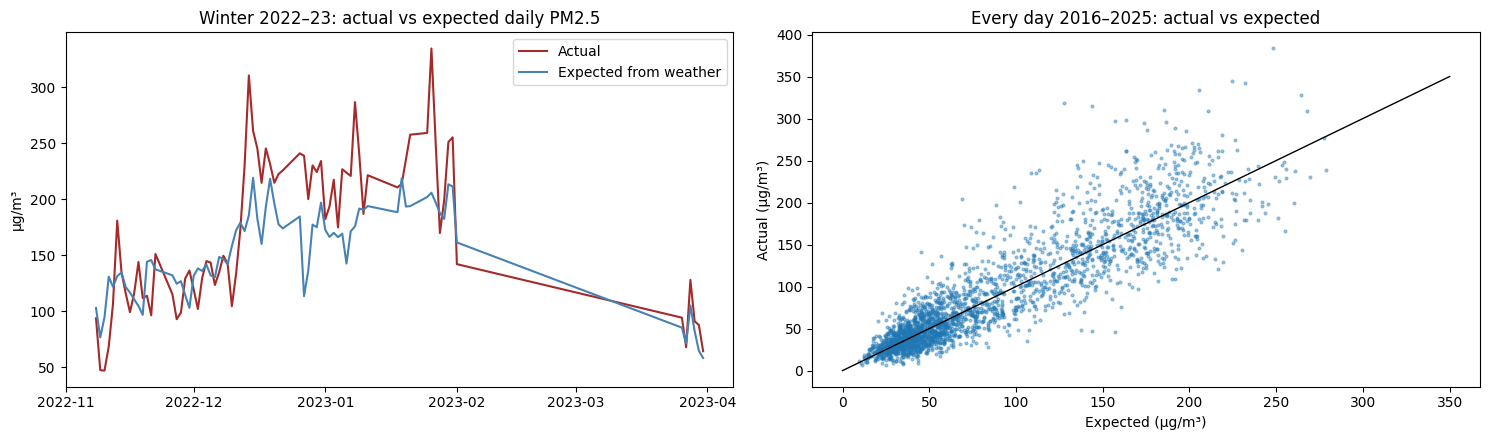

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
w = d.loc["2022-11-01":"2023-03-31"]
ax[0].plot(w.index, w["pm25"], label="Actual", color="brown")
ax[0].plot(w.index, w["expected"], label="Expected from weather", color="steelblue")
ax[0].set_title("Winter 2022–23: actual vs expected daily PM2.5"); ax[0].set_ylabel("µg/m³"); ax[0].legend()
ax[1].scatter(d["expected"], d["pm25"], s=4, alpha=0.4)
ax[1].plot([0, 350], [0, 350], color="black", lw=1)
ax[1].set_xlabel("Expected (µg/m³)"); ax[1].set_ylabel("Actual (µg/m³)")
ax[1].set_title("Every day 2016–2025: actual vs expected")
plt.tight_layout(); plt.show()

date
2016    -7.5
2017    -4.4
2018     6.4
2019     0.7
2020   -10.1
2021    11.1
2022    18.9
2023    24.3
2024     9.9
2025     4.9
Name: adjusted_pct, dtype: float64


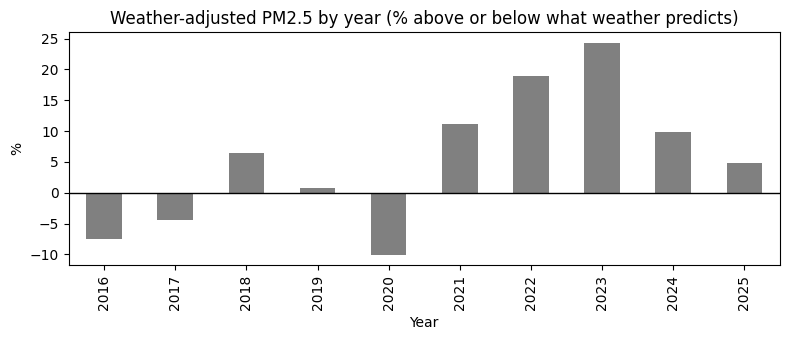

In [5]:
# How far each day was above (+) or below (-) what the weather predicts
d["adjusted_pct"] = (d["pm25"] / d["expected"] - 1) * 100
yearly = d.groupby(d.index.year)["adjusted_pct"].mean()
print(yearly.round(1))
yearly.plot(kind="bar", color="grey", figsize=(8, 3.5))
plt.axhline(0, color="black", lw=1)
plt.title("Weather-adjusted PM2.5 by year (% above or below what weather predicts)")
plt.ylabel("%"); plt.xlabel("Year"); plt.tight_layout(); plt.show()

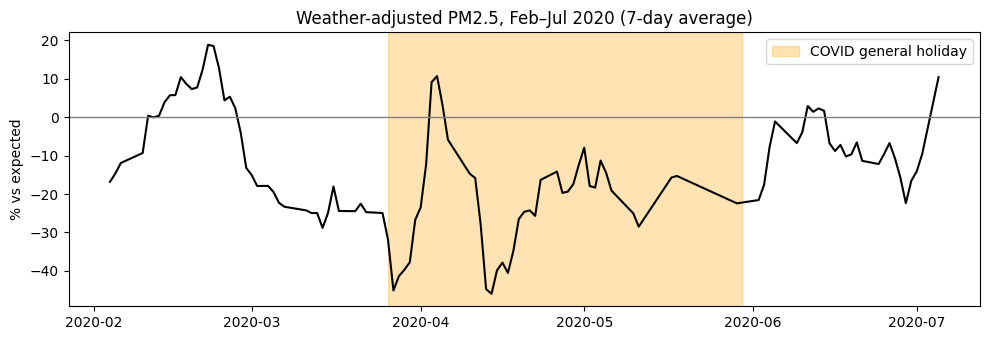

In [6]:
p = d.loc["2020-02-01":"2020-07-15", "adjusted_pct"].rolling(7, center=True).mean()
plt.figure(figsize=(10, 3.5))
plt.plot(p.index, p, color="black")
plt.axvspan(pd.Timestamp("2020-03-26"), pd.Timestamp("2020-05-30"), color="orange", alpha=0.3,
            label="COVID general holiday")
plt.axhline(0, color="grey", lw=1)
plt.title("Weather-adjusted PM2.5, Feb–Jul 2020 (7-day average)")
plt.ylabel("% vs expected"); plt.legend(); plt.tight_layout(); plt.show()

In [7]:
d[["pm25", "expected", "adjusted_pct", "hours"] + FEATURES].to_csv("dhaka_daily_adjusted.csv")
print("Saved", len(d), "days")

Saved 2478 days
